# 模型配置信息profile

In [1]:
from langchain_deepseek import ChatDeepSeek
from dotenv import load_dotenv

load_dotenv(override=True)

model=ChatDeepSeek(
	model="deepseek-flash",
	temperature=2.0,
	max_tokens=100
)

print(model.profile)

{}


输出为空说明平台没有声明DeepSeek官方模型的能力画像

In [5]:
from langchain_openai import  ChatOpenAI
from dotenv import load_dotenv

load_dotenv(override=True)

model=ChatOpenAI(
	model="qwen3.8-flash",
	 base_url="https://dashscope.aliyuncs.com/compatible-mode/v1",
	temperature=2.0,
	max_tokens=100
)

print(model.profile)

{}


# 模型初始化参数(完整版)


## 1.查看初始化参数

### 1.1 查看ChatDeepSeek支持的完整参数列表

In [7]:
from langchain_deepseek import ChatDeepSeek
from rich import  print as rprint
rprint (ChatDeepSeek.model_fields.keys())

dict_keys(['name', 'cache', 'verbose', 'callbacks', 'tags', 'metadata', 'custom_get_token_ids', 'rate_limiter', 
'disable_streaming', 'output_version', 'profile', 'client', 'async_client', 'root_client', 'root_async_client', 
'model_name', 'temperature', 'model_kwargs', 'openai_api_key', 'openai_api_base', 'openai_organization', 
'openai_proxy', 'request_timeout', 'stream_usage', 'max_retries', 'presence_penalty', 'frequency_penalty', 'seed', 
'logprobs', 'top_logprobs', 'logit_bias', 'streaming', 'n', 'top_p', 'max_tokens', 'reasoning_effort', 'reasoning',
'verbosity', 'tiktoken_model_name', 'default_headers', 'default_query', 'http_client', 'http_async_client', 'stop',
'extra_body', 'include_response_headers', 'disabled_params', 'context_management', 'include', 'service_tier', 
'store', 'truncation', 'use_previous_response_id', 'use_responses_api', 'api_key', 'api_base'])

## 1.2 查看ChatOpenAI支持的完整参数列表

In [1]:
from langchain_openai import ChatOpenAI

print(ChatOpenAI.model_fields.keys())

dict_keys(['name', 'cache', 'verbose', 'callbacks', 'tags', 'metadata', 'custom_get_token_ids', 'rate_limiter', 'disable_streaming', 'output_version', 'profile', 'client', 'async_client', 'root_client', 'root_async_client', 'model_name', 'temperature', 'model_kwargs', 'openai_api_key', 'openai_api_base', 'openai_organization', 'openai_proxy', 'request_timeout', 'stream_usage', 'max_retries', 'presence_penalty', 'frequency_penalty', 'seed', 'logprobs', 'top_logprobs', 'logit_bias', 'streaming', 'n', 'top_p', 'max_tokens', 'reasoning_effort', 'reasoning', 'verbosity', 'tiktoken_model_name', 'default_headers', 'default_query', 'http_client', 'http_async_client', 'stop', 'extra_body', 'include_response_headers', 'disabled_params', 'context_management', 'include', 'service_tier', 'store', 'truncation', 'use_previous_response_id', 'use_responses_api'])


In [4]:
from dotenv import load_dotenv
from langchain.chat_models import init_chat_model

load_dotenv(override=True)

test_model=init_chat_model(model="deepseek-flash",
						   model_provider="deepseek")

print(type(test_model).model_fields.keys())

dict_keys(['name', 'cache', 'verbose', 'callbacks', 'tags', 'metadata', 'custom_get_token_ids', 'rate_limiter', 'disable_streaming', 'output_version', 'profile', 'client', 'async_client', 'root_client', 'root_async_client', 'model_name', 'temperature', 'model_kwargs', 'openai_api_key', 'openai_api_base', 'openai_organization', 'openai_proxy', 'request_timeout', 'stream_usage', 'max_retries', 'presence_penalty', 'frequency_penalty', 'seed', 'logprobs', 'top_logprobs', 'logit_bias', 'streaming', 'n', 'top_p', 'max_tokens', 'reasoning_effort', 'reasoning', 'verbosity', 'tiktoken_model_name', 'default_headers', 'default_query', 'http_client', 'http_async_client', 'stop', 'extra_body', 'include_response_headers', 'disabled_params', 'context_management', 'include', 'service_tier', 'store', 'truncation', 'use_previous_response_id', 'use_responses_api', 'api_key', 'api_base'])


查看每个字段的属性

![image.png](images/field.png)
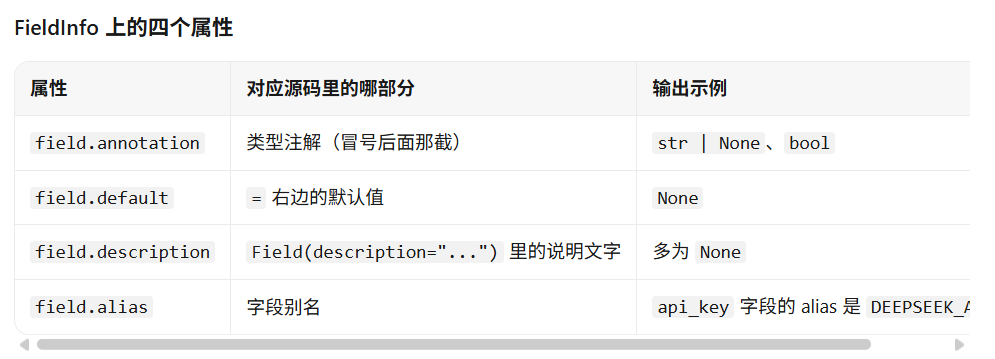

In [6]:
from langchain_deepseek import ChatDeepSeek
for name, field in ChatDeepSeek.model_fields.items():
    print(name)
    print(" annotation:", field.annotation)
    print(" default:", field.default)
    print(" description:", getattr(field, "description", None))
    print(" alias:", field.alias)
    print()

name
 annotation: str | None
 default: None
 description: None
 alias: None

cache
 annotation: langchain_core.caches.BaseCache | bool | None
 default: None
 description: None
 alias: None

verbose
 annotation: <class 'bool'>
 default: PydanticUndefined
 description: None
 alias: None

callbacks
 annotation: list[langchain_core.callbacks.base.BaseCallbackHandler] | langchain_core.callbacks.base.BaseCallbackManager | None
 default: None
 description: None
 alias: None

tags
 annotation: list[str] | None
 default: None
 description: None
 alias: None

metadata
 annotation: dict[str, typing.Any] | None
 default: None
 description: None
 alias: None

custom_get_token_ids
 annotation: collections.abc.Callable[[str], list[int]] | None
 default: None
 description: None
 alias: None

rate_limiter
 annotation: langchain_core.rate_limiters.BaseRateLimiter | None
 default: None
 description: None
 alias: None

disable_streaming
 annotation: typing.Union[bool, typing.Literal['tool_calling']]
 defa

## model_kwargs参数使用
Langchain没有直接列出来的字段，但是模型本身支持，那么可以把参数声明在model_kwargs参数中

In [8]:
from langchain.chat_models import init_chat_model
from dotenv import load_dotenv
from rich import print as rprint
# 从.env文件中加载环境变量
load_dotenv(override=True)
model = init_chat_model(
    model="deepseek:deepseek-v4-flash",
    model_kwargs={"tools": [
        {
            "type": "function",
            "function": {
                "name": "get_weather",
                "description": "Get weather of a location, the user should supply a location first.",
                "parameters": {
                    "type": "object",
                    "properties": {
                        "location": {
                            "type": "string",
                            "description": "The city and state, e.g. SanFrancisco, CA",
                        }
                     },
                    "required": ["location"]
                 },
                }
            },
        ]}
    )
# 向模型发送单条数据
response = model.invoke("你好，今天北京的天气如何")
# 打印响应
rprint(response)

AIMessage(
    content='',
    additional_kwargs={
        'refusal': None,
        'reasoning_content': 'We need answer in Chinese. Need call weather tool. Location Beijing, China maybe 
"Beijing, China". Use get_weather.'
    },
    response_metadata={
        'token_usage': {
            'completion_tokens': 67,
            'prompt_tokens': 320,
            'total_tokens': 387,
            'completion_tokens_details': {
                'accepted_prediction_tokens': None,
                'audio_tokens': None,
                'reasoning_tokens': 26,
                'rejected_prediction_tokens': None
            },
            'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 0},
            'prompt_cache_hit_tokens': 0,
            'prompt_cache_miss_tokens': 320
        },
        'model_provider': 'deepseek',
        'model_name': 'deepseek-flash',
        'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6',
        'id': 'e01005fe-9286-4a7c-957b-20de21063c58',
        'finish_reason': 'tool_calls',
        'logprobs': None
    },
    id='lc_run--01a19a28-cdb9-71c3-b4ec-16b0cf9219e4-0',
    tool_calls=[
        {
            'name': 'get_weather',
            'args': {'location': 'Beijing, China'},
            'id': 'call_00_hsyqP6pbqCor20Q2hK0k0030',
            'type': 'tool_call'
        }
    ],
    invalid_tool_calls=[],
    usage_metadata={
        'input_tokens': 320,
        'output_tokens': 67,
        'total_tokens': 387,
        'input_token_details': {'cache_read': 0},
        'output_token_details': {'reasoning': 26}
    }
)

## extra_body
用于存放厂商基于OpenAI API协议扩展的字段

In [10]:
from langchain.chat_models import init_chat_model
from dotenv import load_dotenv
from rich import print as rprint
# 从.env文件中加载环境变量
load_dotenv(override=True)
model = init_chat_model(
    model="deepseek:deepseek-v4-flash",
    extra_body={"thinking": {"type": "enabled"}},
)
# 向模型发送单条数据
response = model.invoke("你好，一句话回答")
# 打印响应
rprint(response)

AIMessage(
    content='你好！很高兴见到你，有什么我可以帮忙的吗？',
    additional_kwargs={'refusal': None},
    response_metadata={
        'token_usage': {
            'completion_tokens': 11,
            'prompt_tokens': 8,
            'total_tokens': 19,
            'completion_tokens_details': None,
            'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 0},
            'prompt_cache_hit_tokens': 0,
            'prompt_cache_miss_tokens': 8
        },
        'model_provider': 'deepseek',
        'model_name': 'deepseek-flash',
        'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6',
        'id': '59b90a3d-bf9c-4266-9717-47a7b58b8448',
        'finish_reason': 'stop',
        'logprobs': None
    },
    id='lc_run--01a19a2a-6341-71e3-806c-8a8c811a5949-0',
    tool_calls=[],
    invalid_tool_calls=[],
    usage_metadata={
        'input_tokens': 8,
        'output_tokens': 11,
        'total_tokens': 19,
        'input_token_details': {'cache_read': 0},
        'output_token_details': {}
    }
)

## 模型调用中config参数
允许在调用模型时，动态调整配置和控制模型的行为

In [11]:
from langchain.chat_models import init_chat_model
from dotenv import load_dotenv
import os
from rich import print as rprint
# 从.env文件中加载环境变量
load_dotenv(override=True)
DEEPSEEK_API_KEY = os.getenv("DEEPSEEK_API_KEY")
DEEPSEEK_BASE_URL = os.getenv("DEEPSEEK_BASE_URL")
# 1. 初始化模型
model = init_chat_model(
    model="deepseek-v4-flash",
    model_provider="deepseek",
    api_key=DEEPSEEK_API_KEY,
    base_url=DEEPSEEK_BASE_URL,
    temperature=0.2,
    max_tokens=500,
    # 指定可调整参数
    configurable_fields=("model", "model_provider", "temperature","max_tokens"),
)
# 2. 准备 config 字典
config = {
    "run_name": "joke_generation", # 在LangSmith中这次运行会显示为
    "joke_generation"
    "tags": ["tag1", "tag2"], # 打上标签便于分类查找
    "metadata": {"user_id": "123"}, # 记录用户ID
    "configurable":{
        "model": "deepseek-v4-pro", # 配置模型参数
        "model_provider": "openai", # 配置模型提供商参数
        "temperature": 0.7, # 配置温度参数
        "max_tokens": 1000 # 配置最大令牌数
    }
}
# 3. 调用模型并传入config
response = model.invoke(
    "1 + 2 = ？",
    config=config
)
rprint(response)

AIMessage(
    content='1 + 2 = 3',
    additional_kwargs={'refusal': None},
    response_metadata={
        'token_usage': {
            'completion_tokens': 51,
            'prompt_tokens': 90,
            'total_tokens': 141,
            'completion_tokens_details': {
                'accepted_prediction_tokens': None,
                'audio_tokens': None,
                'reasoning_tokens': 43,
                'rejected_prediction_tokens': None
            },
            'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 0},
            'prompt_cache_hit_tokens': 0,
            'prompt_cache_miss_tokens': 90
        },
        'model_provider': 'openai',
        'model_name': 'deepseek-v4-pro',
        'system_fingerprint': 'a307abda487cd1b463329ccb945ce396',
        'id': 'd691d26f-5327-4043-82c9-ba8636ffe70f',
        'finish_reason': 'stop',
        'logprobs': None
    },
    id='lc_run--01a19a30-b077-7419-ab3a-b38aee3b312b-0',
    tool_calls=[],
    invalid_tool_calls=[],
    usage_metadata={
        'input_tokens': 90,
        'output_tokens': 51,
        'total_tokens': 141,
        'input_token_details': {'cache_read': 0},
        'output_token_details': {'reasoning': 43}
    }
)